# 02 Exploratory Analysis
Charts for revenue trend, categories, states, delivery time, delay vs reviews, and orders per customer.
Input: `orders_clean`. Output: figures saved to `reports/figures/`.

In [1]:
# Setup
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.utils import load_orders_clean, get_engine, save_fig

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df = load_orders_clean()
print(df.shape)
df.head(3)

(96470, 20)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delay_days,is_late,purchase_month,customer_unique_id,customer_city,customer_state,items_count,items_value,freight_value,order_value,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,7,-9,0,2017-09,871766c5855e863f6eccc05f988b23cb,campos dos goytacazes,RJ,1,58.9,13.29,72.19,5.0
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,16,-3,0,2017-04,eb28e67c4c0b83846050ddfb8a35d051,santa fe do sul,SP,1,239.9,19.93,259.83,4.0
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,7,-14,0,2018-01,3818d81c6709e39d06b2738a8d3a2474,para de minas,MG,1,199.0,17.87,216.87,5.0


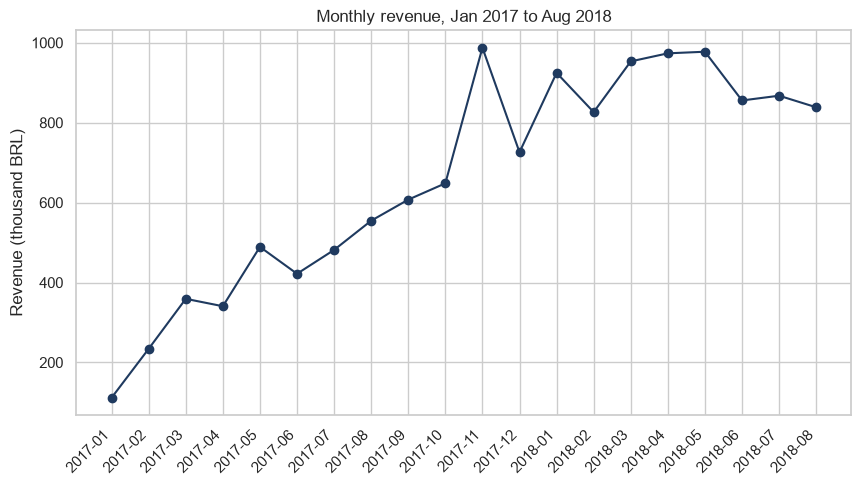

In [2]:
# monthy revenue and orders
monthly = (df.groupby("purchase_month")
             .agg(orders=("order_id", "count"), revenue=("items_value", "sum"))
             .reset_index())
m = monthly[(monthly["purchase_month"] >= "2017-01") & (monthly["purchase_month"] <= "2018-08")]

fig, ax = plt.subplots()
ax.plot(m["purchase_month"], m["revenue"] / 1000, marker="o", color="#1F3A5F")
ax.set_ylabel("Revenue (thousand BRL)")
ax.set_title("Monthly revenue, Jan 2017 to Aug 2018")   # rewrite this to state what you see
plt.xticks(rotation=45, ha="right")
save_fig("01_monthly_revenue")
plt.show()

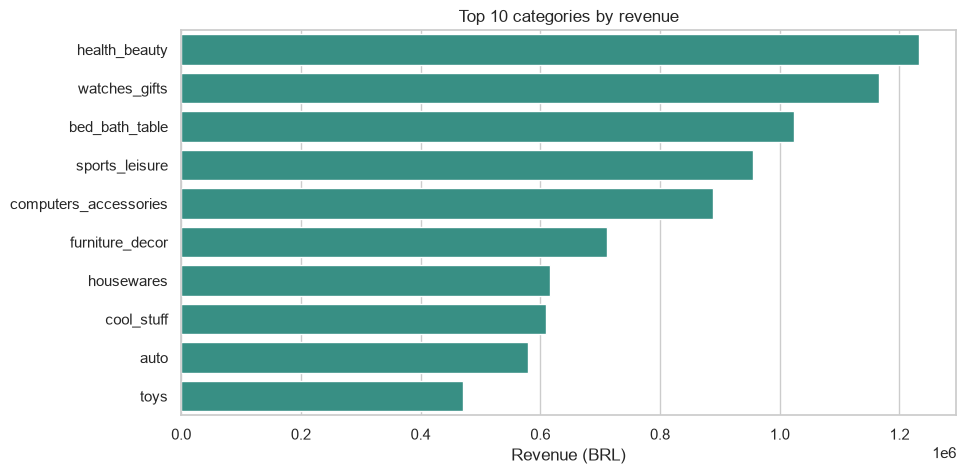

In [3]:
# top 10 caterires 
cat = pd.read_sql("""
    SELECT COALESCE(t.product_category_name_english, 'unknown') AS category,
           ROUND(SUM(oi.price), 2) AS revenue
    FROM order_items oi
    JOIN orders_clean o ON oi.order_id = o.order_id
    JOIN products p ON oi.product_id = p.product_id
    LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
    GROUP BY category
    ORDER BY revenue DESC
    LIMIT 10
""", get_engine())

sns.barplot(data=cat, y="category", x="revenue", color="#2A9D8F")
plt.title("Top 10 categories by revenue")
plt.xlabel("Revenue (BRL)"); plt.ylabel("")
save_fig("02_top_categories")
plt.show()

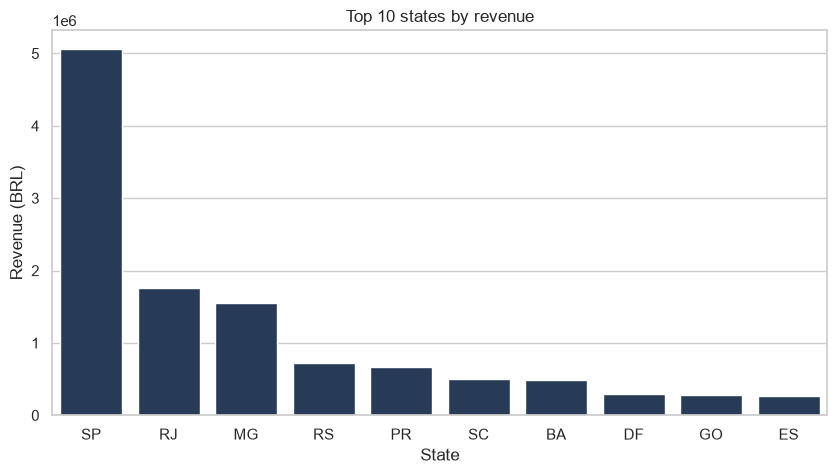

In [4]:
# revenue by state
state = (df.groupby("customer_state")["items_value"].sum()
           .sort_values(ascending=False).head(10).reset_index())
sns.barplot(data=state, x="customer_state", y="items_value", color="#1F3A5F")
plt.title("Top 10 states by revenue"); plt.xlabel("State"); plt.ylabel("Revenue (BRL)")
save_fig("03_revenue_by_state")
plt.show()

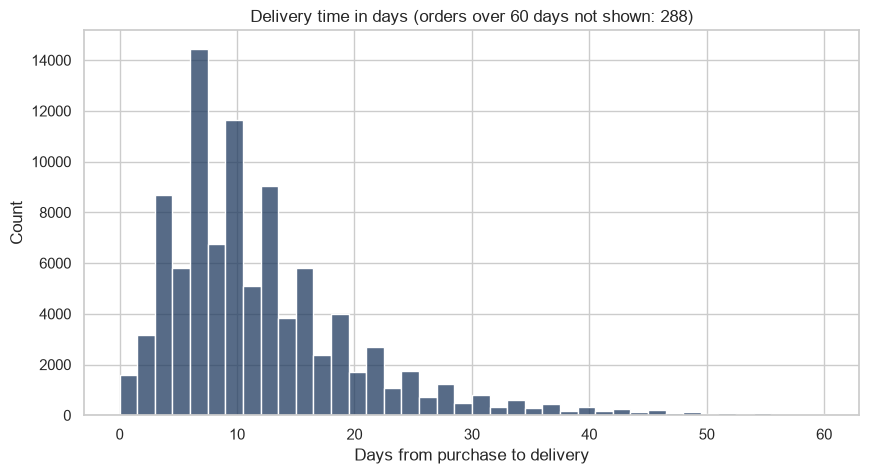

In [5]:
# delivery time distribution 
over = (df["delivery_days"] > 60).sum()
sns.histplot(df.loc[df["delivery_days"] <= 60, "delivery_days"], bins=40, color="#1F3A5F")
plt.title(f"Delivery time in days (orders over 60 days not shown: {over})")
plt.xlabel("Days from purchase to delivery")
save_fig("04_delivery_time")
plt.show()

       delay_bucket  orders  avg_review
0  On time or early   89443        4.29
1     1-3 days late    1852        3.29
2     4-7 days late    1748        2.10
3      8+ days late    2781        1.70


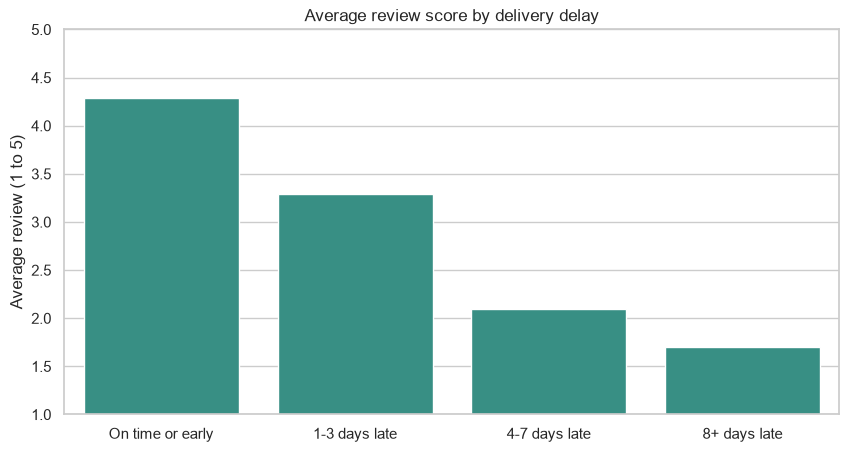

In [6]:
# delay and reviews scores
rv = df.dropna(subset=["review_score"]).copy()
rv["delay_bucket"] = pd.cut(rv["delay_days"], bins=[-1000, 0, 3, 7, 1000],
                            labels=["On time or early", "1-3 days late",
                                    "4-7 days late", "8+ days late"])
b = (rv.groupby("delay_bucket", observed=True)
       .agg(orders=("order_id", "count"), avg_review=("review_score", "mean"))
       .round(2).reset_index())
print(b)

sns.barplot(data=b, x="delay_bucket", y="avg_review", color="#2A9D8F")
plt.ylim(1, 5); plt.title("Average review score by delivery delay")
plt.xlabel(""); plt.ylabel("Average review (1 to 5)")
save_fig("05_delay_vs_review")
plt.show()

1 order      97.0
2 orders      2.8
3 orders      0.2
4+ orders     0.1
Name: count, dtype: float64


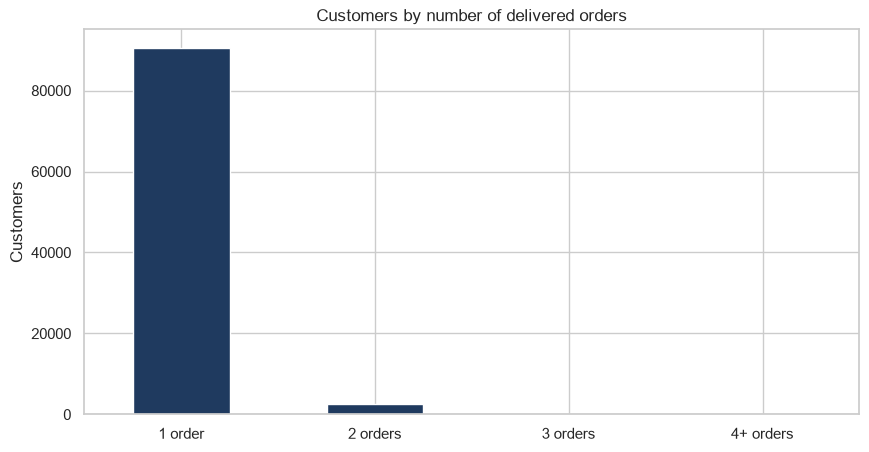

In [7]:
# how many orders per customers
n = df.groupby("customer_unique_id").size().clip(upper=4).value_counts().sort_index()
n.index = ["1 order", "2 orders", "3 orders", "4+ orders"]
print((n / n.sum() * 100).round(1))
n.plot(kind="bar", color="#1F3A5F", rot=0)
plt.title("Customers by number of delivered orders"); plt.ylabel("Customers")
save_fig("06_orders_per_customer")
plt.show()